# Random-halves test of the Gaussian covariance (filament samples)

**Question.** The fits use a Gaussian covariance of $\hat\xi_0$ built from each sample's measured power spectrum
(`bf.gaussian_cov_pk`). It contains the sample's excess noise (clumpiness) only at the Gaussian level. Fil is very clumpy
(excess noise ≈ 16× Poisson at k = 0.15), so the higher-order part of its noise, which the Gaussian formula leaves out,
could matter. This notebook tests the noise part of the covariance directly, on the data, without mocks.

**Idea.** Split a sample X at random into two halves $H_1$, $H_2$ (each galaxy goes to one half with probability 1/2) and take
the difference of their monopoles,

$$
\boxed{\;\boldsymbol\Delta=\hat{\boldsymbol\xi}_{0,H_1}-\hat{\boldsymbol\xi}_{0,H_2}\;}
$$

Both halves trace the same density field, so the pure signal × signal (cosmic variance) term cancels in Δ. What is left
is signal × noise and noise × noise: exactly the terms that depend on the noise model. The Gaussian formula predicts the
covariance of Δ, $\mathsf C_\Delta$ (section 2). If it is right, then for each split

$$
\chi^2=\boldsymbol\Delta^{\rm T}\,\mathsf C_\Delta^{-1}\,\boldsymbol\Delta
$$

follows a χ² distribution with $n$ degrees of freedom, $n$ = number of bins, so $\langle\chi^2\rangle=n$. If the noise is
underestimated by a factor $1+\varepsilon$ (i.e. the true covariance of Δ is $(1+\varepsilon)\,\mathsf C_\Delta$), then $\langle\chi^2\rangle=n(1+\varepsilon)$.

**Control.** The same test on Full dil nFil (same N as Fil, randomly chosen galaxies, nearly Poisson noise). The Gaussian
covariance should pass there; the question is whether Fil behaves differently.

**What it does not test.** The cosmic-variance (signal × signal) part of the covariance, which cancels in Δ.

**Settings** are in the next cell and printed by it. Pair counts of the halves are cached in
`data/processed/covariance_tests/` (one file per sample and settings), so re-running is fast; nothing else is written.

In [1]:
import os, sys, time, warnings
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from Corrfunc.theory.DD import DD
warnings.filterwarnings('ignore')

REPO = os.path.abspath(os.path.join(os.getcwd(), '..', '..', '..'))   # notebooks/exploratory/<this folder>
sys.path.insert(0, os.path.join(REPO, 'src'))
sys.path.insert(0, os.path.join(REPO, 'scripts'))
import bao_fitting as bf
import multidark_analysis as ma          # the measurement script: same catalogue, cuts and subsamples

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.25, 'lines.linewidth': 1.6})

# ---------------- settings (change here only) ----------------
test_samples = ['Fil', 'Full dil nFil']     # tested samples (labels as below); e.g. add 'NonFil', 'Full dil nNonFil'
n_splits = 50                               # random splits per sample
split_seed = 1                              # seed of the first split (split r uses split_seed + r)
binsep = 2.5                                # bin width [h^-1 Mpc], as the fits
fit_range = (50., 150.)                     # separations tested [h^-1 Mpc], as the fits
mono_sep = (5.0, 150.0)                     # separation range of the monopole files (for the bias, as the fits)
nthreads = 8                                # Corrfunc threads
check_spectra = False                       # True: measure the spectra of one split (section 5; a few minutes)
force_recompute = False                     # True: recount the pairs of the halves even if cached
# -------------------------------------------------------------
L, mag = ma.L, ma.mag_max
# sample -> <bin_desc> of its files (as desilike_fits); the random dilutions are added below
samples = {'Full': 'full',
           'Fil': '0.0leqd_mathrmfilleq3.0',
           'NonFil': '10.0leqd_mathrmfilleq100.0'}
pk_file = os.path.join(ma.spectra_dir, f'pk_{ma.run_name}.npz')
MONO = ma.monopoles_dir
CACHE = os.path.join(REPO, 'data', 'processed', 'covariance_tests')
os.makedirs(CACHE, exist_ok=True)
edges = np.arange(fit_range[0], fit_range[1] + 1e-9, binsep)
s = 0.5 * (edges[1:] + edges[:-1]); n_bins = len(s)

lin = bf.linear_theory()
T = bf.BAOTemplate(*bf.generate_templates(lin=lin), lin)
spec = bf.load_spectra(pk_file)
for lab in ('Fil', 'NonFil'):            # random dilutions of Full with the N of Fil / NonFil, as in desilike_fits
    if samples.get(lab) in spec['labels']:
        n = spec['n_gal'][spec['labels'].index(samples[lab])]
        dil = [l for l, nn in zip(spec['labels'], spec['n_gal']) if l.startswith('FullrandomN-') and nn == n]
        if dil:
            samples[f'Full dil n{lab}'] = dil[0]

print(f"run {ma.run_name}: mag < {mag}, box L = {L:g};  spectra file {os.path.basename(pk_file)}")
print(f"tested: {test_samples};  {n_splits} splits each (seeds {split_seed}..{split_seed + n_splits - 1})")
print(f"{n_bins} bins of {binsep:g} h^-1 Mpc in {fit_range}")
print("samples: " + ", ".join(f"{l} = '{k}'" for l, k in samples.items()))

run XISMU_box_mag-20.8_dist_fil: mag < -20.8, box L = 1000;  spectra file pk_XISMU_box_mag-20.8_dist_fil.npz
tested: ['Fil', 'Full dil nFil'];  50 splits each (seeds 1..50)
40 bins of 2.5 h^-1 Mpc in (50.0, 150.0)
samples: Full = 'full', Fil = '0.0leqd_mathrmfilleq3.0', NonFil = '10.0leqd_mathrmfilleq100.0', Full dil nFil = 'FullrandomN-1043082r20261016', Full dil nNonFil = 'FullrandomN-2176035r20261016'


## 1. Samples

The catalogue, magnitude cut, filament bins and random dilutions are made by the measurement script itself
(`scripts/multidark_analysis.py`: `load_catalog`, `select_sample`, `make_samples`), with its current settings, so these are
the same galaxies as in the monopole and spectra files of the run. The cell checks N against the spectra file.

For each sample the cell also gets $b$, the bias that enters the covariance below $k_{\rm lo}$, exactly as the fits
(`bf.estimate_bias_independent` on the sample's monopole file).

In [2]:
cat = ma.select_sample(ma.load_catalog(os.path.join(ma.RAW_DIR, 'to_mock.csv'),
                                       os.path.join(ma.RAW_DIR, 'mock_withfilament.csv')), mag)
by_desc = {desc: g for _, desc, g, _ in ma.make_samples(cat)}
pos, bias = {}, {}
for lab in test_samples:
    key = samples[lab]
    g = by_desc[key]
    n_spec = int(spec['n_gal'][spec['labels'].index(key)])
    assert len(g) == n_spec, f"{lab}: {len(g)} galaxies here, {n_spec} in the spectra file"
    pos[lab] = np.ascontiguousarray(g[['x', 'y', 'z']].values, dtype=np.float64)
    f = os.path.join(MONO, f'mag={mag:.1f}_sep={mono_sep[0]:.1f}-{mono_sep[1]:.1f}_binsep={binsep:.1f}_{key}.npz')
    s_m, xi_m, n_m = bf.load_monopole(f)
    bias[lab] = bf.estimate_bias_independent(s_m, xi_m, bf.edges_from_centres(s_m), n_m / L**3, T)['b']
    print(f"{lab:<16} N = {len(g):>8d}   b(cov) = {bias[lab]:.3f}")
del cat, by_desc

Control: random 1043082 of 4999875 Full galaxies (matches '$0.0 \leq d_{\mathrm{fil}} \leq 3.0$', seed 20261016)
Control: random 2176035 of 4999875 Full galaxies (matches '$10.0 \leq d_{\mathrm{fil}} \leq 100.0$', seed 20261016)
Fil              N =  1043082   b(cov) = 1.384
Full dil nFil    N =  1043082   b(cov) = 0.961


## 2. Predicted covariance of the difference

**Spectra of the halves.** Write the measured power of X (shot noise not subtracted) as
$P_X(k)=S_X(k)+1/\bar n_X$, where $1/\bar n_X$ is the Poisson term (each galaxy paired with itself) and $S_X$ is everything else,
including the excess noise from galaxies that sit close together. A random split thins every pair of distinct galaxies
by the same factor, so $S_X$ is the same for the halves and for their cross-spectrum; only the self-pair term changes.
Each half has $\bar n_X/2$, so

$$
P_{11}=P_{22}=S_X+\frac{2}{\bar n_X}=P_X+\frac1{\bar n_X},\qquad P_{12}=S_X=P_X-\frac1{\bar n_X}.
$$

These are exact expectations for a random split, so the halves' spectra need not be measured (section 5 checks it).

**Covariance.** `bf.gaussian_cov_pk` for the two halves together, with these spectra and the bias of X, gives the joint
covariance $\begin{pmatrix}\mathsf C_{11}&\mathsf C_{12}\\ \mathsf C_{21}&\mathsf C_{22}\end{pmatrix}$, and

$$
\boxed{\;\mathsf C_\Delta=\mathsf C_{11}+\mathsf C_{22}-\mathsf C_{12}-\mathsf C_{21}\;}
$$

This uses the same recipe as the fits (the same `spectrum_for_cov` patches at low and very high k). The cell prints
$\sqrt{C_{\Delta,ii}}$ next to the error $\sqrt{C_{ii}}$ of X itself.

In [3]:
def halves_spec(spec, key):
    # spectra dict of the two random halves of sample `key`, from the measured spectrum of the sample
    i = spec['labels'].index(key)
    nbar = spec['n_gal'][i] / spec['L']**3
    P = spec['P'][i, i]
    out = dict(spec)
    out['P'] = np.array([[P + 1 / nbar, P - 1 / nbar], [P - 1 / nbar, P + 1 / nbar]])
    out['labels'] = ['H1', 'H2']
    out['n_gal'] = np.array([spec['n_gal'][i] / 2] * 2)
    return out

C_D = {}
for lab in test_samples:
    Cj = bf.gaussian_cov_pk(edges, halves_spec(spec, samples[lab]), [0, 1], [bias[lab]] * 2, lin)
    C_D[lab] = Cj[:n_bins, :n_bins] + Cj[n_bins:, n_bins:] - Cj[:n_bins, n_bins:] - Cj[n_bins:, :n_bins]
    C_X = bf.gaussian_cov_pk(edges, spec, [spec['labels'].index(samples[lab])], [bias[lab]], lin)
    print(f"{lab:<16} at s = " + ", ".join(f"{x:g}" for x in s[::10]) + ":  sqrt(C_Delta) = "
          + ", ".join(f"{x:.2e}" for x in np.sqrt(np.diag(C_D[lab]))[::10]) + ";  sqrt(C_X) = "
          + ", ".join(f"{x:.2e}" for x in np.sqrt(np.diag(C_X))[::10]))

Fil              at s = 51.25, 76.25, 101.25, 126.25:  sqrt(C_Delta) = 1.40e-03, 9.39e-04, 7.05e-04, 5.66e-04;  sqrt(C_X) = 2.67e-03, 1.77e-03, 1.32e-03, 1.06e-03
Full dil nFil    at s = 51.25, 76.25, 101.25, 126.25:  sqrt(C_Delta) = 7.17e-04, 4.81e-04, 3.61e-04, 2.89e-04;  sqrt(C_X) = 7.87e-04, 5.29e-04, 3.91e-04, 3.13e-04


## 3. The random splits

For split $r$ every galaxy of X goes to $H_1$ or $H_2$ with probability 1/2 (seed `split_seed` + r), and

$$
\hat\xi_{0,H}(s_i)=\frac{DD_H(s_i)}{RR_H(s_i)}-1,\qquad RR_H(s_i)=\frac{N_H(N_H-1)}{L^3}\,V_i,
$$

the estimator of the pipeline ($DD_H$ = ordered pair counts of the half in bin $i$, $V_i$ = volume of the spherical shell
of bin $i$; in real space this equals the μ-averaged monopole of the monopole files). The cell checks that the mean of the
two halves agrees with the monopole of X.

Different splits use independent coin flips, so their Δ are uncorrelated (Δ is linear in the ±1 assignments of the
galaxies), and the $n_{\rm splits}$ values of χ² can be averaged.

In [4]:
def dd(p):
    # ordered pair counts of p in the bins `edges` (Corrfunc counts each pair twice in an auto-count)
    r = DD(autocorr=1, nthreads=nthreads, binfile=edges, X1=p[:, 0], Y1=p[:, 1], Z1=p[:, 2],
           periodic=True, boxsize=L, verbose=False)
    return r['npairs'].astype(np.float64)

def xi_hat(p):
    N = len(p)
    return dd(p) / (N * (N - 1) / L**3 * 4 * np.pi / 3 * (edges[1:]**3 - edges[:-1]**3)) - 1

D, xi_mean = {}, {}
t0 = time.time()
for lab in test_samples:
    f = os.path.join(CACHE, f"halves_{samples[lab]}_mag{mag:.1f}_s{fit_range[0]:g}-{fit_range[1]:g}"
                            f"_bin{binsep:g}_seed{split_seed}.npz")
    old = np.load(f) if os.path.exists(f) and not force_recompute else None
    done = 0 if old is None or not np.allclose(old['edges'], edges) else len(old['D'])
    rows, means = (list(old['D']), list(old['xi_mean'])) if done else ([], [])
    for r in range(done, n_splits):
        h = np.random.default_rng(split_seed + r).random(len(pos[lab])) < 0.5
        x1, x2 = xi_hat(pos[lab][h]), xi_hat(pos[lab][~h])
        rows.append(x1 - x2); means.append(0.5 * (x1 + x2))
        np.savez(f, D=np.array(rows), xi_mean=np.array(means), edges=edges)
    D[lab], xi_mean[lab] = np.array(rows)[:n_splits], np.array(means)[:n_splits]
    xi_X = xi_hat(pos[lab])
    print(f"{lab:<16} {len(D[lab])} splits ({n_splits - min(done, n_splits)} new, {time.time() - t0:.0f} s);  "
          f"max |mean of halves - xi_X| / sqrt(C_Delta) = "
          f"{np.max(np.abs(xi_mean[lab].mean(0) - xi_X) / np.sqrt(np.diag(C_D[lab]))):.3f}")

Fil              50 splits (50 new, 303 s);  max |mean of halves - xi_X| / sqrt(C_Delta) = 0.041
Full dil nFil    50 splits (50 new, 656 s);  max |mean of halves - xi_X| / sqrt(C_Delta) = 0.066


## 4. The test

For each sample and split, $\chi^2_r=\boldsymbol\Delta_r^{\rm T}\mathsf C_\Delta^{-1}\boldsymbol\Delta_r$ over the $n$ bins. The table gives:

* $\langle\chi^2\rangle/n$ over the splits, with its expected scatter $\sqrt{2/(n\,n_{\rm splits})}$ if the covariance is right
  (then it should be 1 within that scatter). $\hat\varepsilon=\langle\chi^2\rangle/n-1$ estimates by how much the Gaussian
  covariance under- (ε > 0) or over- (ε < 0) estimates the noise, averaged over the directions of the data vector.
* The p-value of the Kolmogorov–Smirnov test of the $\chi^2_r$ against a χ² distribution with $n$ degrees of freedom.

Left: histogram of $\chi^2_r$ and the χ²$_n$ distribution. Right: per bin, $r_i=\langle\Delta_i^2\rangle/C_{\Delta,ii}$, the measured
variance over the predicted one (expected 1, scatter $\sqrt{2/n_{\rm splits}}$ per bin, grey band); this shows on which scales a
failure happens. Neighbouring bins are correlated, so runs of $r_i$ above or below 1 are expected.

n = 40 bins, 50 splits;  expected <chi2>/n = 1 +- 0.032
sample              <chi2>/n   eps_hat  (sigmas)    KS p
Fil                    1.035    +0.035      +1.1   0.702
Full dil nFil          0.995    -0.005      -0.1   0.976


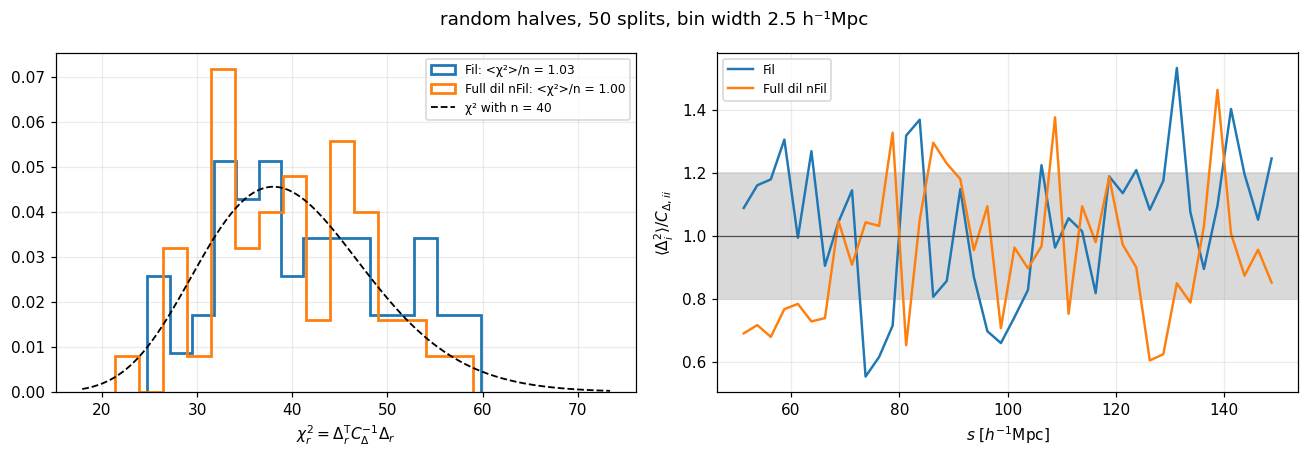

In [5]:
res = {}
for lab in test_samples:
    Ci = np.linalg.inv(C_D[lab])
    chi2 = np.einsum('ri,ij,rj->r', D[lab], Ci, D[lab])
    res[lab] = dict(chi2=chi2, r=np.mean(D[lab]**2, axis=0) / np.diag(C_D[lab]),
                    ks=stats.kstest(chi2, stats.chi2(n_bins).cdf).pvalue)

sig = np.sqrt(2 / (n_bins * n_splits))
print(f"n = {n_bins} bins, {n_splits} splits;  expected <chi2>/n = 1 +- {sig:.3f}")
print(f"{'sample':<18}{'<chi2>/n':>10}{'eps_hat':>10}{'(sigmas)':>10}{'KS p':>8}")
for lab, r in res.items():
    m = r['chi2'].mean() / n_bins
    print(f"{lab:<18}{m:>10.3f}{m - 1:>+10.3f}{(m - 1) / sig:>+10.1f}{r['ks']:>8.3f}")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.2))
xx = np.linspace(stats.chi2(n_bins).ppf(0.001), stats.chi2(n_bins).ppf(0.999), 300)
for j, (lab, r) in enumerate(res.items()):
    c = f'C{j}'
    a1.hist(r['chi2'], bins=15, density=True, histtype='step', lw=1.8, color=c,
            label=f"{lab}: <χ²>/n = {r['chi2'].mean() / n_bins:.2f}")
    a2.plot(s, r['r'], color=c, label=lab)
a1.plot(xx, stats.chi2(n_bins).pdf(xx), 'k--', lw=1.2, label=f'χ² with n = {n_bins}')
a1.set_xlabel(r'$\chi^2_r=\Delta_r^{\rm T}C_\Delta^{-1}\Delta_r$'); a1.legend(fontsize=8)
a2.axhspan(1 - np.sqrt(2 / n_splits), 1 + np.sqrt(2 / n_splits), color='0.85', zorder=0)
a2.axhline(1, color='0.3', lw=0.8)
a2.set_xlabel(r'$s\ [h^{-1}{\rm Mpc}]$'); a2.set_ylabel(r'$\langle\Delta_i^2\rangle / C_{\Delta,ii}$'); a2.legend(fontsize=8)
fig.suptitle(f'random halves, {n_splits} splits, bin width {binsep:g} h⁻¹Mpc'); fig.tight_layout(); plt.show()

## 5. Optional check: the spectra of the halves

Section 2 derives the halves' spectra from the spectrum of X instead of measuring them. With `check_spectra = True` the
cell measures the auto- and cross-spectra of the halves of split 0 with the same settings as the run
(`multidark_power.measure_spectra`, a few minutes per sample) and prints measured / derived for $P_{11}$, $P_{22}$, $P_{12}$,
averaged over a few k ranges, as (measured − derived) / $P_X$: the difference in units of the total power of X. It should be
≈ 0 up to the scatter of the measurement (largest at low k, where there are few modes). (A plain ratio would be meaningless
for $P_{12}$ of a nearly Poisson sample, where $P_{12}\approx 0$ at high k.)

In [6]:
if check_spectra:
    from multidark_power import measure_spectra
    k_ranges = ((0.02, 0.1), (0.1, 0.3), (0.3, 1.0), (1.0, 2.8))
    for lab in test_samples:
        h = np.random.default_rng(split_seed).random(len(pos[lab])) < 0.5
        sp = measure_spectra([pos[lab][h], pos[lab][~h]], ['H1', 'H2'], L, ng=ma.pk_ngrid,
                             n_fold=ma.pk_n_fold, kuse_frac=ma.pk_kuse_frac)
        der = halves_spec(spec, samples[lab])
        assert np.allclose(sp['k'], der['k']), "k bins differ from the spectra file"
        w = sp['nmodes']
        iX = spec['labels'].index(samples[lab]); PX = spec['P'][iX, iX]
        for name, (a, b) in (('P11', (0, 0)), ('P22', (1, 1)), ('P12', (0, 1))):
            rel = []
            for lo, hi in k_ranges:
                m = (sp['k'] >= lo) & (sp['k'] < hi)
                rel.append(np.sum(w[m] * (sp['P'][a, b][m] - der['P'][a, b][m])) / np.sum(w[m] * PX[m]))
            print(f"{lab:<16} {name}: (measured - derived) / P_X = " +
                  ", ".join(f"{r:+.3f} (k {lo}-{hi})" for r, (lo, hi) in zip(rel, k_ranges)))
else:
    print("check_spectra = False: skipped")

check_spectra = False: skipped
